**420-C74-SF - Techniques d'apprentissage automatique - Automne 2026 - Spécialiste en solutions d'intelligence artificielle**<br/>
© 2026 MKL.AI - Tous droits réservés
<br/>
![Atelier - Comparaison kNN et régression logistique](static/13-banner.png)
<br/>
**Objectif:** cette séance de travaux pratiques a pour objectif la comparaison des deux types de classificateurs vus en cours jusqu'à présent, à savoir la régression logistique et la classification kNN. Leur mise en oeuvre sera réalisée à l'aide de la librairie **scikit-learn** et la notion de **compromis biais-variance** sera étudiée. Le travail sera basé sur le jeu de données **Heart** entrevu précédemment

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline

## 0 - Chargement des bibliothèques

In [2]:
# Manipulation de données
import numpy as np
import pandas as pd

# Visualisation de données
import matplotlib.pyplot as plt
import seaborn as sns

# Helpers pour l'affichage
from helpers import plot_classifier

# Outils divers
from tqdm import tqdm
from collections import defaultdict

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


In [3]:
# Configuration de la visualisation
sns.set(style="darkgrid")
sns.set_context("notebook", font_scale=1.5, rc={"lines.linewidth": 2.5})

## 1 - Lecture du jeu de données

<strong style="color: #006db4">Exercice 1-1: lire le fichier `Heart.csv`<strong/>

In [4]:
# Compléter le code ci-dessous ~ 1-2 lignes

HRT = pd.read_csv('../../data/Heart.csv', index_col=0)

In [5]:
# On supprime tout de suite les données manquantes. Ceci sera vu plus en détail plus tard dans le cours
HRT = HRT.dropna()

<strong style="color: #006db4">Exercice 1-2: afficher les dix premières lignes de la trame de données HRT</strong>

In [6]:
# Compléter le code ci-dessous ~ 1 ligne

HRT.head(10)

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
6,56,1,nontypical,120,236,0,0,178,0,0.8,1,0.0,normal,No
7,62,0,asymptomatic,140,268,0,2,160,0,3.6,3,2.0,normal,Yes
8,57,0,asymptomatic,120,354,0,0,163,1,0.6,1,0.0,normal,No
9,63,1,asymptomatic,130,254,0,2,147,0,1.4,2,1.0,reversable,Yes
10,53,1,asymptomatic,140,203,1,2,155,1,3.1,3,0.0,reversable,Yes


## 2 - Visualisation des données

La première étape avant toute étude d'apprentissage supervisé consiste à (essayer de) visualiser les données (voir cours de *Visualisation des données*). Cette étape est faite ici pour vous.

Remarque: l'affichage ci-dessous peut prendre quelques dizaines de secondes ...

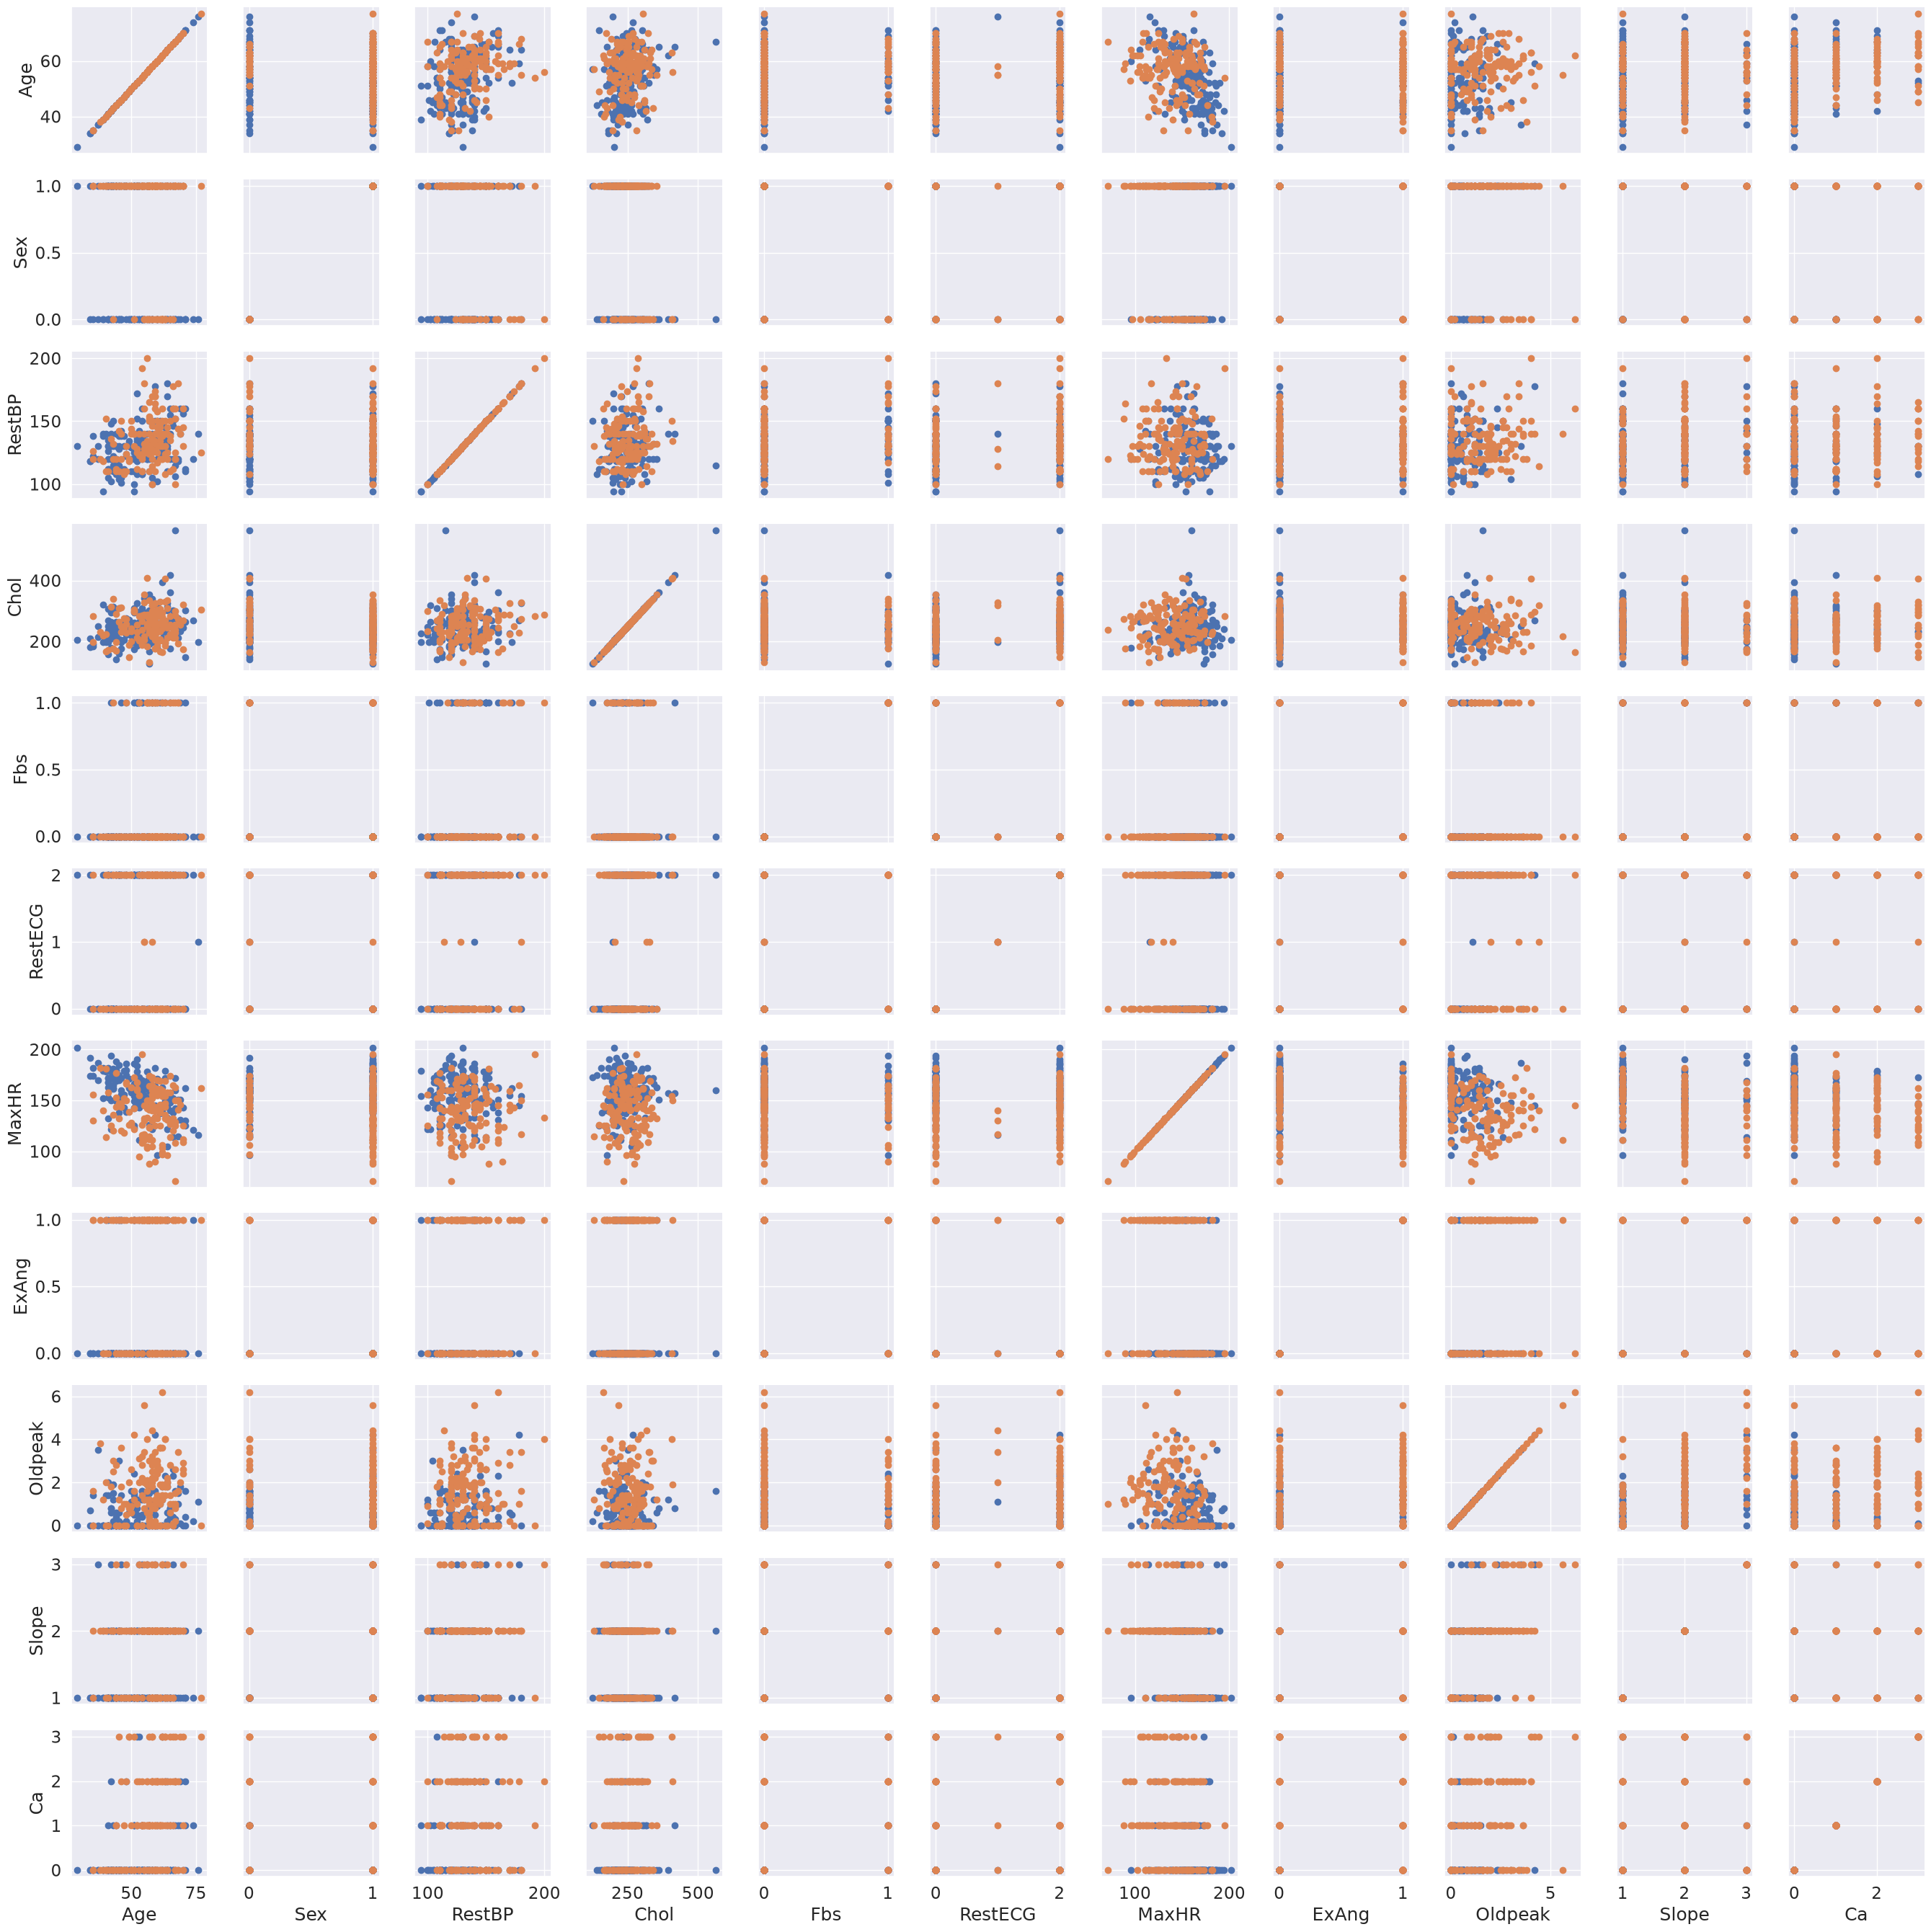

In [7]:
g = sns.PairGrid(HRT, hue="AHD")
g = g.map(plt.scatter)

Pour la suite de l'exercice, nous allons considérer uniquement les variables explicatives `Age` et `MaxHR`, ainsi que bien évidemment la variable réponse `AHD`

<strong style="color: #006db4">Exercice 2-1: créer une nouvelle trame de données ne contenant que les variables `Age`, `MaxHR` et `AHD`</strong>

In [8]:
# Compléter le code ci-dessous ~ 1 ligne

HRT2 = HRT[['Age', 'MaxHR', 'AHD']]

<strong style="color: #006db4">Exercice 2-2: afficher les dix premières lignes de la nouvelle trame de données `HRT2`</strong>

In [9]:
# Compléter le code ci-dessous ~ 1 ligne

HRT2.head(10)

,Age,MaxHR,AHD
1,63,150,No
2,67,108,Yes
3,67,129,Yes
4,37,187,No
5,41,172,No
6,56,178,No
7,62,160,Yes
8,57,163,No
9,63,147,Yes
10,53,155,Yes


## 3 - Affichage de HRT2

<Axes: xlabel='Age', ylabel='MaxHR'>

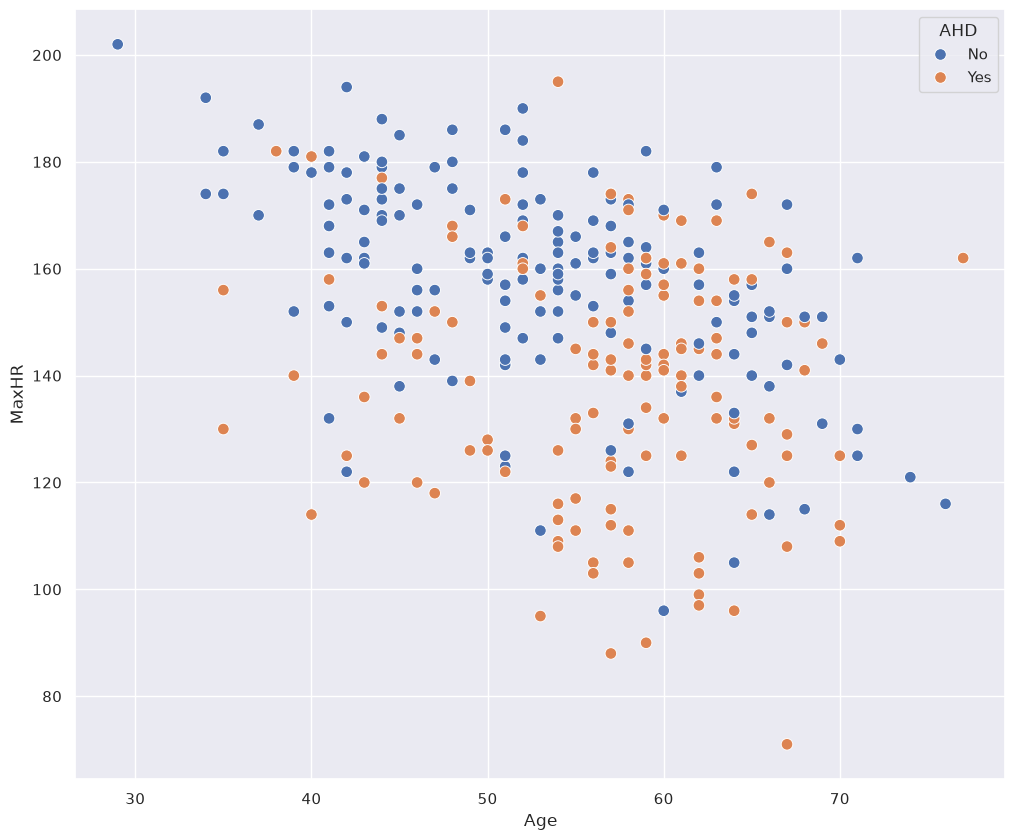

In [10]:
sns.set(style="darkgrid", rc={'figure.figsize':(12,10)})
sns.scatterplot(x='Age', y='MaxHR', hue="AHD", data=HRT2, s=70)

## 4 - Préparation des données en vue d'effectuer la validation des résultats des classificateurs

<strong style="color: #006db4">Exercice 4-1: extraire les variables explicatives dans un numpy array `X` et la variable réponse dans un vecteur `y`</strong>

In [11]:
# Compléter le code ci-dessous ~ 2 lignes

X = HRT2[['Age', 'MaxHR']].values
y = HRT2['AHD'].map({'No': 0, 'Yes': 1}).values

<strong style="color: #006db4">Exercice 4-2: à l'aide de scikit-learn, sépararer les données en jeu d'entraînement et jeu de test. La taille du jeu de test doit représenter 30% de la taille du jeu de données initial et l'état du générateur aléatoire sera fixé à 2020 afin de permettre la reproductibilité</strong>

In [12]:
# Compléter le code ci-dessous ~ 2 lignes

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2020)

In [13]:
print(f'X_train: {X_train.shape[0]} observations')
print(f'X_test: {X_test.shape[0]} observations')

X_train: 207 observations
X_test: 90 observations


## 5 - Régression logistique simple

<strong style="color: #006db4">Exercice 5-1: à l'aide de scikit-learn, effectuez la standardisation des données. Nommez les données standardisées `X1_scaled`</strong>

In [15]:
# Compléter le code ci-dessous ~ 3 lignes

scaler = StandardScaler()
X1_scaled = scaler.fit_transform(X_train)

<strong style="color: #006db4">Exercice 5-2: à l'aide de scikit-learn, entraînez un modèle de régression logistique. Désactivez la régularisation.</strong>

<details>
<summary>
    <font size="3" color="darkgreen"><b>Cliquer ici pour obtenir un indice</b></font>
</summary>
<p>
<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html"> class sklearn.linear_model.LogisticRegression(penalty='l2', *, dual=False, tol=0.0001, C=1.0, fit_intercept=True, intercept_scaling=1, class_weight=None, random_state=None, solver='lbfgs', max_iter=100, multi_class='auto', verbose=0, warm_start=False, n_jobs=None, l1_ratio=None)</a>
</p>

In [16]:
# Compléter le code ci-dessous ~ 1 ligne

# C=np.inf <=> aucune régularisation (penalty=None est déprécié depuis scikit-learn 1.8)
clf1 = LogisticRegression(C=np.inf).fit(X1_scaled, y_train)

#### Affichage des résultats

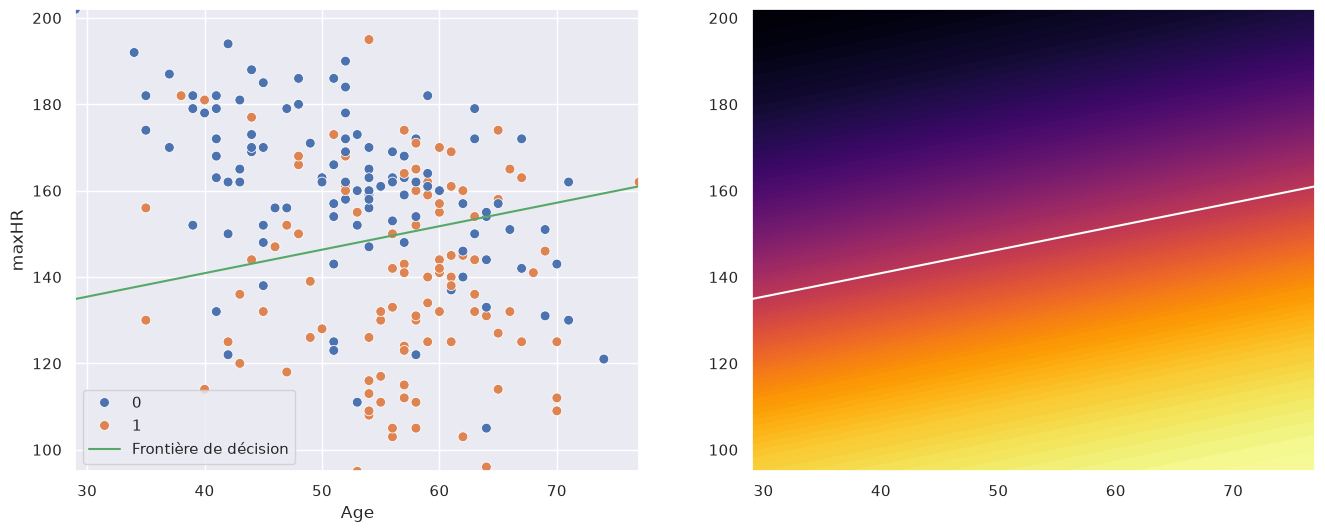

In [18]:
sns.set(rc={'figure.figsize':(16,6)})
plot_classifier(X_train, y_train, clf1, scaler, order=1, xlabel="Age", ylabel="maxHR")

<strong style="color: #006db4">Exercice 5-3: évaluez les performances sur le jeu d'entraînement. De quelle métrique s'agit-il ?</strong>

In [19]:
# Compléter le code ci-dessous ~ 1 ligne

# score() retourne l'exactitude (accuracy) pour un classificateur
clf1.score(X1_scaled, y_train)

0.6956521739130435

**Réponse :** `score()` retourne l'**exactitude** (*accuracy*), c'est-à-dire la proportion d'observations correctement classées. Ici, elle est calculée sur le jeu d'entraînement.

<strong style="color: #006db4">Exercice 5-4: évaluez maintenant les performances sur le jeu de test</strong>

In [20]:
# Compléter le code ci-dessous ~ 2-3 lignes

# Le scaler est ajusté sur le jeu d'entraînement seulement
X1_test_scaled = scaler.transform(X_test)
clf1.score(X1_test_scaled, y_test)

0.6666666666666666

## 6 - Régression logistique avec variables d'interaction et variables polynomiales d'ordre 2

<strong style="color: #006db4">Exercice 6-1: à l'aide de scikit-learn, construisez la matrice des prédicteurs `X2` en incluant les variables d'interactions et les variables polynomiales d'ordre 2. N'incluez pas le biais (ou intercept)</strong>

<details>
<summary>
    <font size="3" color="darkgreen"><b>Cliquer ici pour obtenir un indice</b></font>
</summary>
<p>
<a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html"> class class sklearn.preprocessing.PolynomialFeatures(degree=2, *, interaction_only=False, include_bias=True, order='C')</a>
</p>

In [21]:
# Compléter le code ci-dessous ~ 1-2 lignes

poly2 = PolynomialFeatures(degree=2, include_bias=False)
X2 = poly2.fit_transform(X_train)

<strong style="color: #006db4">Exercice 6-2: à l'aide de scikit-learn, standardisez la matrice des prédicteurs</strong>

In [22]:
# Compléter le code ci-dessous ~ 1-3 lignes

scaler = StandardScaler()
X2_scaled = scaler.fit_transform(X2)

<strong style="color: #006db4">Exercice 6-3:  l'aide de scikit-learn, entraînez un modèle de régression logistique. Comme précédemment, désactivez la régularisation.</strong>

In [23]:
# Compléter le code ci-dessous ~ 1 ligne

clf2 = LogisticRegression(C=np.inf).fit(X2_scaled, y_train)

#### Affichage des résultats

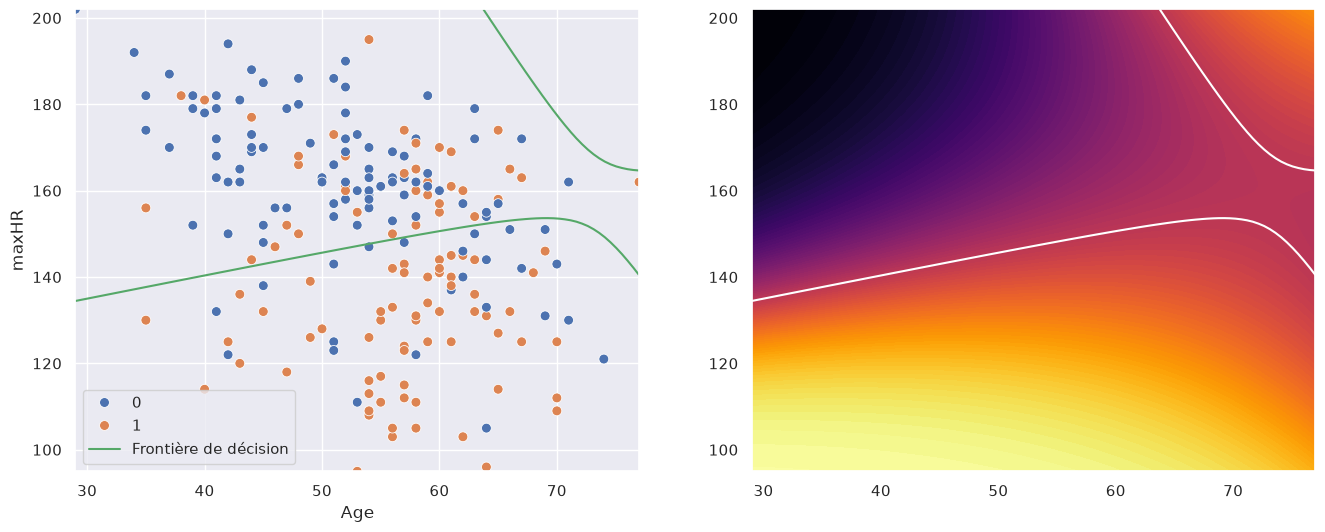

In [24]:
sns.set(rc={'figure.figsize':(16,6)})
plot_classifier(X_train, y_train, clf2, scaler, order=2, xlabel="Age", ylabel="maxHR")

<strong style="color: #006db4">Exercice 6-4: évaluez les performances sur le jeu d'entraînement</strong>

In [25]:
# Compléter le code ci-dessous ~ 1 ligne

clf2.score(X2_scaled, y_train)

0.6956521739130435

<strong style="color: #006db4">Exercice 6-5: évaluez maintenant les performances sur le jeu de test</strong>

In [26]:
# Compléter le code ci-dessous ~ 2-3 lignes

X2_test_scaled = scaler.transform(poly2.transform(X_test))
clf2.score(X2_test_scaled, y_test)

0.6444444444444445

## 7 - Régression logistique avec variables d'interaction et variables polynomiales d'ordre 3

<strong style="color: #006db4">Exercice 7-1: construisez la matrice des prédicteurs `X3` incluant les variables d'interactions et les variables polynomiales d'ordre 3. Ne pas inclure le biais (ou intercept)</strong>

In [27]:
# Compléter le code ci-dessous ~ 1-2 lignes

poly3 = PolynomialFeatures(degree=3, include_bias=False)
X3 = poly3.fit_transform(X_train)

<strong style="color: #006db4">Exercice 7-2: standardisez la matrice des prédicteurs</strong>

In [28]:
# Compléter le code ci-dessous ~ 1-3 lignes

scaler = StandardScaler()
X3_scaled = scaler.fit_transform(X3)

<strong style="color: #006db4">Exercice 7-3: entraînez un modèle de régression logistique. Comme précédemment, désactivez la régularisation. Quel paramètre supplémentaire devez-vous changer ?</strong>

In [29]:
# Compléter le code ci-dessous ~ 1 ligne

# Il faut augmenter le nombre maximal d'itérations (max_iter) pour que l'algorithme converge
clf3 = LogisticRegression(C=np.inf, max_iter=10000).fit(X3_scaled, y_train)

**Réponse :** avec des variables polynomiales d'ordre 3 (et plus), l'algorithme d'optimisation (`lbfgs`) n'a pas le temps de converger avec les 100 itérations par défaut (`ConvergenceWarning`). Il faut augmenter le nombre maximal d'itérations `max_iter`.

#### Affichage des résultats

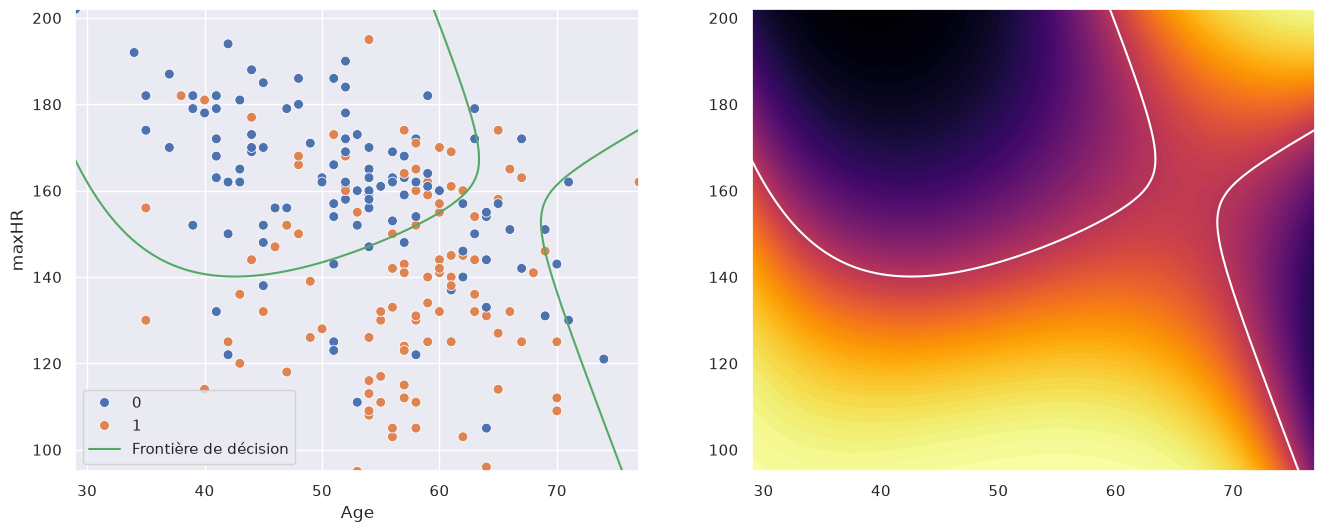

In [30]:
sns.set(rc={'figure.figsize':(16,6)})
plot_classifier(X_train, y_train, clf3, scaler, order=3, xlabel="Age", ylabel="maxHR")

<strong style="color: #006db4">Exercice 7-4: évaluez les performances sur le jeu d'entraînement</strong>

In [31]:
# Compléter le code ci-dessous ~ 1 ligne

clf3.score(X3_scaled, y_train)

0.7053140096618358

<strong style="color: #006db4">Exercice 7-5: évaluez maintenant les performances sur le jeu de test</strong>

In [32]:
# Compléter le code ci-dessous ~ 2-3 lignes

X3_test_scaled = scaler.transform(poly3.transform(X_test))
clf3.score(X3_test_scaled, y_test)

0.7

## 8 - Régression logistique avec variables d'interaction et variables polynomiales d'ordre 6

<strong style="color: #006db4">Exercice 8-1: construisez la matrice des prédicteurs `X6` incluant les variables d'interactions et les variables polynomiales d'ordre 6. Ne pas inclure le biais (ou intercept)</strong>

In [33]:
# Compléter le code ci-dessous ~ 1-2 lignes

poly6 = PolynomialFeatures(degree=6, include_bias=False)
X6 = poly6.fit_transform(X_train)

<strong style="color: #006db4">Exercice 8-2: standardisez la matrice des prédicteurs</strong>

In [34]:
# Compléter le code ci-dessous ~ 1-3 lignes

scaler = StandardScaler()
X6_scaled = scaler.fit_transform(X6)

<strong style="color: #006db4">Exercice 8-3: entraînez un modèle de régression logistique. Comme précédemment, désactivez la régularisation.</strong>

In [35]:
# Compléter le code ci-dessous ~ 1 ligne

clf6 = LogisticRegression(C=np.inf, max_iter=100000).fit(X6_scaled, y_train)

#### Affichage des résultats

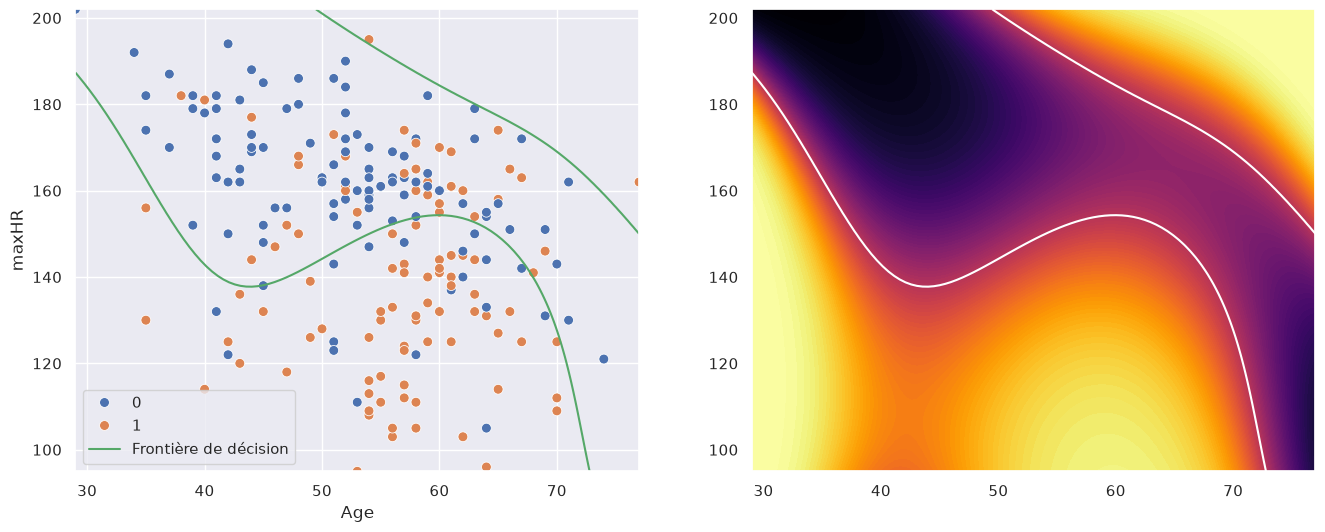

In [36]:
sns.set(rc={'figure.figsize':(16,6)})
plot_classifier(X_train, y_train, clf6, scaler, order=6, xlabel="Age", ylabel="maxHR")

<strong style="color: #006db4">Exercice 8-4: évaluez les performances sur le jeu d'entraînement</strong>

In [37]:
# Compléter le code ci-dessous ~ 1 ligne

clf6.score(X6_scaled, y_train)

0.7342995169082126

<strong style="color: #006db4">Exercice 8-5: évaluez maintenant les performances sur le jeu de test</strong>

In [38]:
# Compléter le code ci-dessous ~ 2-3 lignes

X6_test_scaled = scaler.transform(poly6.transform(X_test))
clf6.score(X6_test_scaled, y_test)

0.7

## 9 - Classification kNN

<strong style="color: #006db4">Exercice 9-1: à l'aide de scikit-learn, entraînez un modèle de classification KNN. Choisissez K=22</strong>

<details>
<summary>
    <font size="3" color="darkgreen"><b>Cliquer ici pour obtenir un indice</b></font>
</summary>
<p>
<a href="https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html">class sklearn.neighbors.KNeighborsClassifier(n_neighbors=5, *, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=None, **kwargs)</a>
</p>

In [39]:
# Compléter le code ci-dessous ~ 2 lignes

neigh = KNeighborsClassifier(n_neighbors=22)
neigh.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",22
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


#### Affichage des résultats

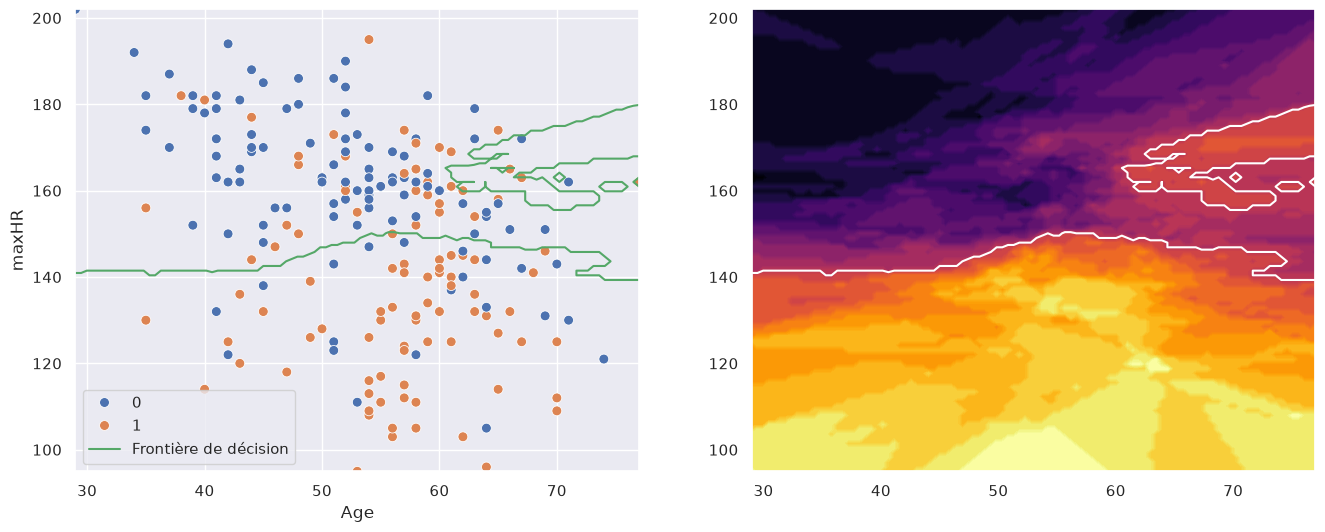

In [40]:
sns.set(rc={'figure.figsize':(16,6)})
plot_classifier(X_train, y_train, neigh, scaler=None, xlabel="Age", ylabel="maxHR")

<strong style="color: #006db4">Exercice 9-2: évaluez les performances sur le jeu d'entraînement</strong>

In [41]:
# Compléter le code ci-dessous ~ 1 ligne

neigh.score(X_train, y_train)

0.7198067632850241

<strong style="color: #006db4">Exercice 9-3: évaluez maintenant les performances sur le jeu de test</strong>

In [42]:
# Compléter le code ci-dessous ~ 1 ligne

neigh.score(X_test, y_test)

0.6666666666666666

<strong style="color: #006db4">Exercice 9-4: Essayez d'autres valeurs de K. Quelle est selon la valeur de K offrant un bon compromis biais-variance?</strong>

In [43]:
# Exactitude (accuracy) en entraînement et en test pour différentes valeurs de K
for k in [1, 5, 10, 22, 50, 100, 150]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"K = {k:3d} - train = {knn.score(X_train, y_train):.3f} - test = {knn.score(X_test, y_test):.3f}")

K =   1 - train = 0.986 - test = 0.611
K =   5 - train = 0.739 - test = 0.711
K =  10 - train = 0.734 - test = 0.722
K =  22 - train = 0.720 - test = 0.667
K =  50 - train = 0.710 - test = 0.678
K = 100 - train = 0.720 - test = 0.644
K = 150 - train = 0.715 - test = 0.644


**Réponse :**

| Modèle | Accuracy entraînement | Accuracy test |
|---|---|---|
| Régression logistique - ordre 1 | 0,696 | 0,667 |
| Régression logistique - ordre 2 | 0,696 | 0,644 |
| Régression logistique - ordre 3 | 0,705 | 0,700 |
| Régression logistique - ordre 6 | 0,734 | 0,700 |
| kNN - K = 22 | 0,720 | 0,667 |

- Pour la régression logistique, la flexibilité augmente avec l'ordre du polynôme : l'accuracy d'entraînement augmente, mais l'accuracy de test ne suit pas forcément. La frontière de décision de l'ordre 6 devient très irrégulière (variance élevée).
- Pour le kNN, c'est l'inverse : la flexibilité **diminue** quand `K` augmente.
  - `K = 1` : accuracy d'entraînement ≈ 99 % mais accuracy de test ≈ 61 % → surapprentissage (faible biais, variance élevée).
  - `K` très grand (100, 150) : la frontière devient presque constante, les deux accuracies se dégradent → sous-apprentissage (biais élevé, faible variance).
  - Une valeur de `K` autour de **5 à 10** offre ici un bon compromis biais-variance (accuracy de test ≈ 71-72 %, proche de l'accuracy d'entraînement ≈ 73-74 %).
- Attention : avec seulement 90 observations de test, une observation vaut ≈ 1,1 % d'accuracy. Choisir `K` sur le jeu de test introduit un biais optimiste ; il faudrait plutôt utiliser la validation croisée (atelier 11).

## 10 - Recherche des meilleurs hyperparamètres

### 10 - 1 - Préparation des jeux de données

Nous allons maintenant considérer l'ensemble des variables explicatives du jeu de données **Heart**

<strong style="color: #006db4">Exercice 10-1-1: Encoder les variables explicatives catégorielles. Indice: utilisez pandas ;-)</strong>

In [44]:
# Compléter le code ci-dessous ~ 2-3 lignes

# Variables explicatives à k niveaux => k-1 variables indicatrices (drop_first=True)
X = pd.get_dummies(HRT.drop(['AHD'], axis=1), drop_first=True, dtype=int).values
y = HRT['AHD'].map({'No': 0, 'Yes': 1}).values

<strong style="color: #006db4">Exercice 10-1-2: Quel est le nombre de variables explicatives ?</strong>

In [45]:
# Compléter le code ci-dessous ~ 1 ligne

X.shape[1]

16

<strong style="color: #006db4">Exercice 10-1-3: à l'aide de scikit-learn, sépararer les données en jeu d'entraînement et jeu de test. La taille du jeu de test doit représenter 30% de la taille du jeu de données et l'état du générateur aléatoire sera fixé à 2020 afin de permettre la reproductibilité</strong>

In [46]:
# Compléter le code ci-dessous ~ 1 ligne

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2020)

### 10 - 2  - Régression logistique

<strong style="color: #006db4">Exercice 10-2: réalisez plusieurs fois une régression logistique polynomiale (cette fois-ci SANS variables d'interaction) en faisant varier l'ordre `n` de 1 à 15. Vous pouvez utiliser la fonction `polynomial` ci-dessous. Enregistrez les scores sur les jeux d'entraînement et de test pour chaque valeur de `n` dans le dictionnaire `history`</strong>

In [47]:
def polynomial(X, degree=2):
    vec = [np.ones((X.shape[0],1))]
    for d in range(1,degree+1):
        temp = np.array((X**d))
        vec.append(temp)
    return np.hstack(vec)

In [48]:
history = defaultdict(list)
for n in tqdm(range(1,15)):
    # Compléter le code ci-dessous ~ quelques lignes ...
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(polynomial(X_train, degree=n))
    X_test_scaled = scaler.transform(polynomial(X_test, degree=n))
    clf = LogisticRegression(max_iter=10000)
    clf.fit(X_train_scaled, y_train)

    history['train'].append(clf.score(X_train_scaled, y_train))
    history['test'].append(clf.score(X_test_scaled, y_test))

  0%|          | 0/14 [00:00<?, ?it/s]

100%|██████████| 14/14 [00:00<00:00, 97.18it/s] 


#### Affichage de la courbe de validation

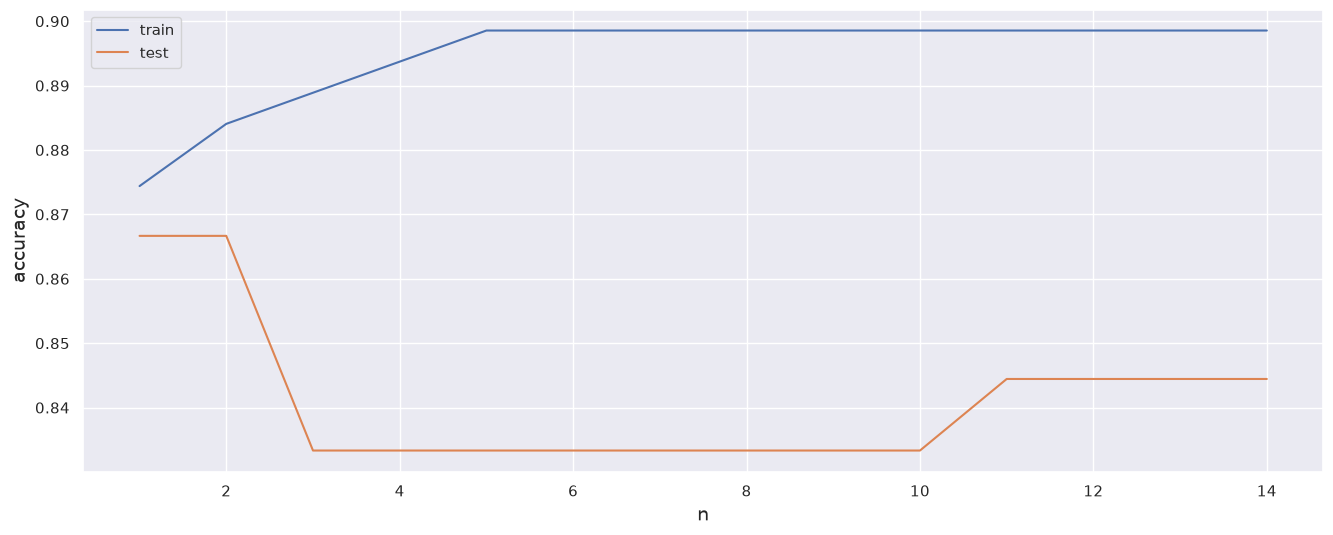

In [49]:
f, ax = plt.subplots(1,1)
ax.plot(range(1,15), history['train'], label="train")
ax.plot(range(1,15), history['test'], label="test")
ax.set_xlabel('n', fontsize=14)
ax.set_ylabel('accuracy', fontsize=14)
ax.legend()

### 10 - 3  - Classification kNN

<strong style="color: #006db4">Exercice 10-3: réalisez plusieurs fois une classification kNN en faisant varier le nombre de voisins `k` de 1 à 200. Enregistrez les scores sur les jeux d'entraînement et de test pour chaque valeur de `n` dans le dictionnaire `history`</strong>

In [50]:
history = defaultdict(list)

# Standardisation : indispensable pour kNN qui repose sur des distances
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

for k in tqdm(range(1,200)):
    # Compléter le code ci-dessous ~ quelques lignes ...
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    history['train'].append(knn.score(X_train_scaled, y_train))
    history['test'].append(knn.score(X_test_scaled, y_test))

  0%|          | 0/199 [00:00<?, ?it/s]

100%|██████████| 199/199 [00:01<00:00, 185.83it/s]


#### Affichage de la courbe de validation

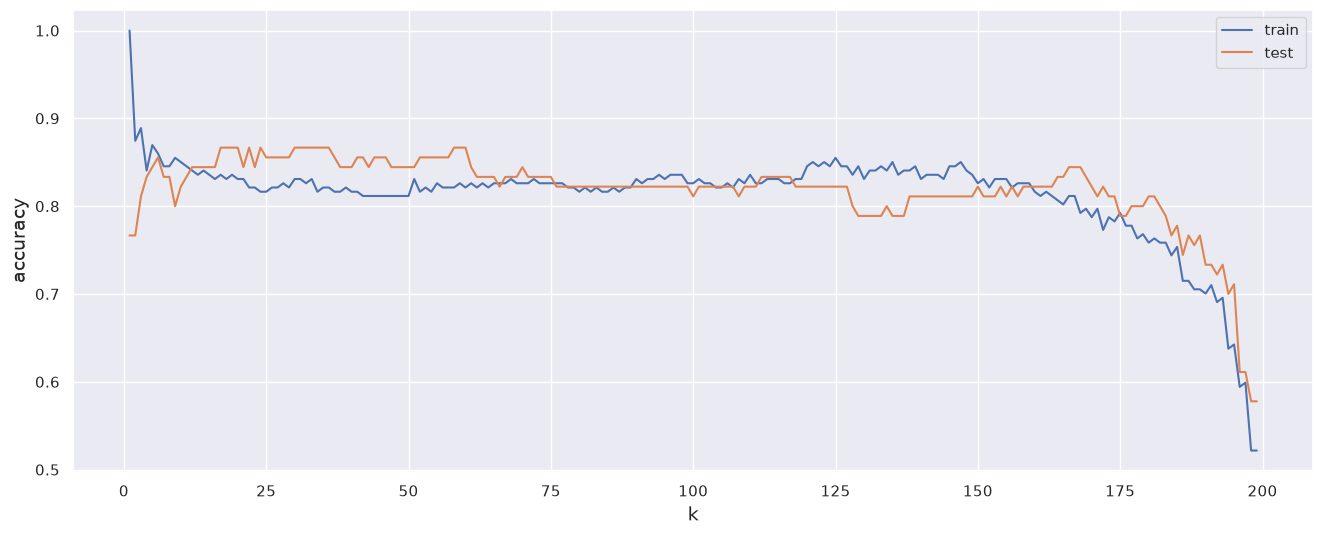

In [51]:
f, ax = plt.subplots(1,1)
ax.plot(range(1,200),history['train'], label="train")
ax.plot(range(1,200), history['test'], label="test")
ax.set_xlabel('k', fontsize=14)
ax.set_ylabel('accuracy', fontsize=14)
ax.legend()

### 11 - 3 - Choix du modèle

<strong style="color: #006db4">Exercice 11-3: Quel modèle choisissez-vous ? Quels sont les valeurs des hyperparamètres ?</strong>

**Réponse :**

| Modèle | Hyperparamètre | Accuracy entraînement | Accuracy test |
|---|---|---|---|
| Régression logistique polynomiale | `n = 1` (ou `n = 2`) | ≈ 0,874 | ≈ 0,867 |
| kNN (données standardisées) | `k ≈ 17-19` | ≈ 0,836 | ≈ 0,867 |

- Régression logistique : l'accuracy d'entraînement augmente avec `n` (jusqu'à ≈ 0,90) alors que l'accuracy de test baisse à partir de `n = 3` → les ordres élevés n'apportent rien et surajustent légèrement.
- kNN : `k = 1` surajuste (100 % en entraînement, ≈ 77 % en test). L'accuracy de test plafonne autour de 0,84-0,87 pour `k` entre 13 et 50 environ, puis s'effondre quand `k` approche la taille du jeu d'entraînement (le modèle prédit presque toujours la classe majoritaire).

Les deux modèles atteignent la même accuracy de test. On retient la **régression logistique d'ordre `n = 1`** : c'est le modèle le plus simple, il est interprétable (coefficients) et l'écart entraînement/test est faible (bon compromis biais-variance).

Remarque : comme les hyperparamètres ont été choisis en regardant le jeu de test, l'accuracy de test est une estimation optimiste. La bonne pratique consiste à sélectionner les hyperparamètres par validation croisée sur le jeu d'entraînement, puis à évaluer une seule fois le modèle final sur le jeu de test.

### Fin de l'atelier